# Unsupervised Learning: PCA & Clustering

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/konstantin-schekotihin/dl_course/blob/master/AI-ML/07_unsupervised.ipynb)

In [1]:
# Setup & configuration (skip in presentation slides)
%matplotlib inline
from IPython.display import Markdown, display
import matplotlib.image as mpimg
import numpy as np
import pandas as pd
import seaborn as sns
from ipywidgets import fixed, interact
from scipy.cluster.hierarchy import cophenet, fcluster, linkage
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Course helpers: installed from PyPI in Colab, from the repository's .venv locally
import sys
if "google.colab" in sys.modules:
    %pip install -q dl-course
from dl_course import aiml as hp
hp.setup_theme()

## 1. Foundations of Unsupervised Learning

<center>
    <img src="https://raw.githubusercontent.com/konstantin-schekotihin/dl_course/master/shared/images/unsupervised.jpg" width="80%"/>
</center>

### Goals and Challenges of Unsupervised Learning

+ What should we do, if there are no labels?
    - There is no simple goal for analysis, the methods are more subjective
    - However, these methods are very important in various applications 
+ Can we represent the data in some informative way and study its properties?

+ Results are hard to check: without a response there is no error to measure on validation or test data, and no cross-validation to tell us whether we did a good job

+ Examples:
    - Documents can be grouped by words occurring in them
    - Patients by results of various tests
    - Products by technical features
+ Unlabeled data is often easier to get! 
    - No mighty oracle providing the labels is required

### Supervised vs. Unsupervised Paradigms
+ Dimensionality reduction:
    - Given a set of features and their observations, can we derive new features that are better suitable for analysis?
    - *Principal Components Analysis* (PCA): a tool used for data visualization or data preprocessing before supervised techniques are applied

## 2. Principal Components Analysis (PCA)
+ Assume you face a dataset with a large set of correlated features
+ PCA allows us to summarize this set with a smaller number of "synthetic" features that collectively explain most of the variance in the original dataset
+ Given a dataset with $N$ observations of $D$ features

<small>📖 *Source: [James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). An Introduction to Statistical Learning with Applications in Python, Ch. 12: Unsupervised Learning. Springer](https://doi.org/10.1007/978-3-031-38747-0_12)*</small>

### Motivating Case Study: US Arrests

+ Consider a data set containing statistics for each of the 50 US states in 1973:
    - arrests per 100,000 residents for assault, murder, and rape;
    - percent of the population living in urban areas

In [2]:
# Load USArrests dataset
us = pd.read_csv(hp.get_file("USArrests.csv"))
states = us.pop(us.columns[0])
us.head()


,Murder,Assault,UrbanPop,Rape
0,13.2,236,58,21.2
1,10.0,263,48,44.5
2,8.1,294,80,31.0
3,8.8,190,50,19.5
4,9.0,276,91,40.6


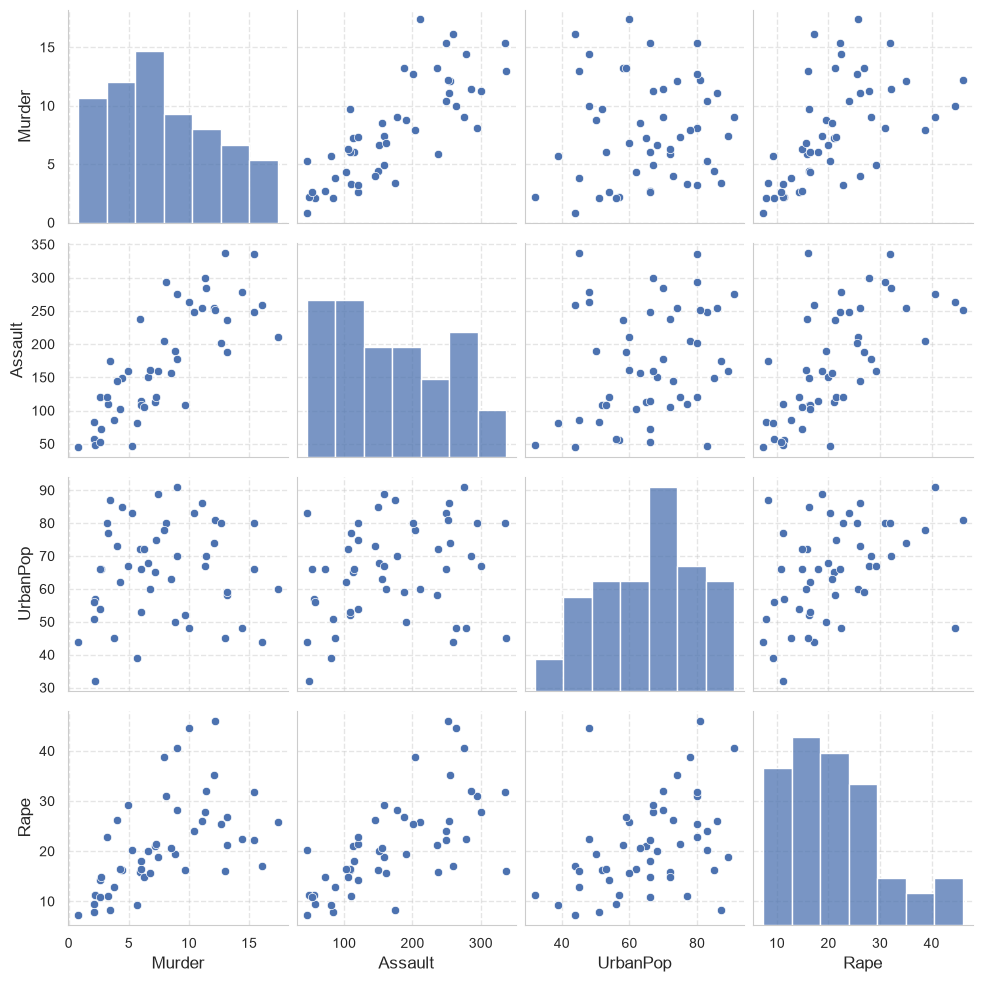

In [3]:
sns.pairplot(us);

In [4]:
us.describe()

,Murder,Assault,UrbanPop,Rape
count,50.00000,50.000000,50.000000,50.000000
mean,7.78800,170.760000,65.540000,21.232000
std,4.35551,83.337661,14.474763,9.366385
min,0.80000,45.000000,32.000000,7.300000
25%,4.07500,109.000000,54.500000,15.075000
50%,7.25000,159.000000,66.000000,20.100000
75%,11.25000,249.000000,77.750000,26.175000
max,17.40000,337.000000,91.000000,46.000000


### Feature Standardization

- Because variance depends on the measurement units, we standardize each feature column to zero mean and unit variance whenever the features are measured in different units (here: arrests per 100,000 residents and percent):

$$
x_{ni}' = \frac{x_{ni} - \bar{x}_i}{s_i}
$$

- where sample mean $\bar{x}_i$ and standard deviation $s_i$ are defined as:

$$
\bar{x}_i = \frac{1}{N} \sum_{n=1}^{N} x_{ni}, \quad s_i = \sqrt{\frac{1}{N-1} \sum_{n=1}^{N} (x_{ni} - \bar{x}_i)^2}
$$

> 💡 **Key Takeaway:** Unstandardized features with large numerical magnitudes dominate distances and principal component variances. With features in the same units, standardizing is a modelling choice.

In [5]:
def standardize(X):
    """Standardize the columns of X to zero mean and unit variance (sample standard deviation)."""
    return (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)

# The first two columns (Murder, Assault) for the 2D example
X_us = standardize(us.to_numpy(dtype=float))[:, [0, 1]]
df_us = pd.DataFrame(data=X_us, columns=us.columns[[0, 1]])
df_us.describe()

,Murder,Assault
count,5.000000e+01,5.000000e+01
mean,-5.384582e-17,1.110223e-16
std,1.000000e+00,1.000000e+00
min,-1.604405e+00,-1.509042e+00
25%,-8.524835e-01,-7.410815e-01
50%,-1.235217e-01,-1.411127e-01
75%,7.948553e-01,9.388312e-01
max,2.206860e+00,1.994776e+00


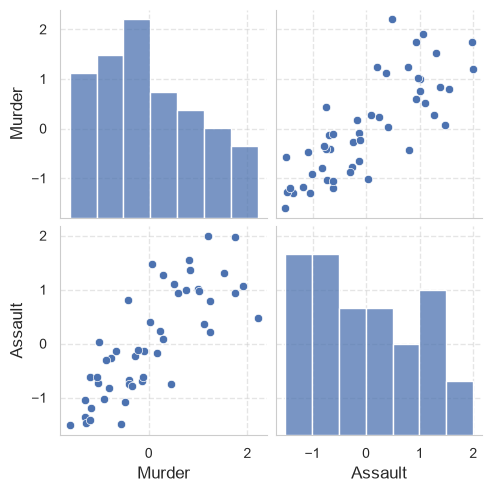

In [6]:
sns.pairplot(df_us);

In [7]:
def plot_scores(x=0, y=0):
    """Projection of the 2D data onto the direction (x, y)."""
    hp.plot_pca_scores(X_us, [x, y], x_label=us.columns[0], y_label=us.columns[1])

In [8]:
interact(plot_scores, x=fixed(1), y=(-1, 1, 0.2));

interactive(children=(FloatSlider(value=0.0, description='y', max=1.0, min=-1.0, step=0.2), Output()), _dom_cl…

### Principal Components & Direction Vectors

- For data matrix $\mathbf{X} \in \mathbb{R}^{N \times D}$ with centered observation vectors $\mathbf{x}_n \in \mathbb{R}^D$:
- The first **principal component** projection is a linear combination defined by unit direction vector $\mathbf{u}_1 \in \mathbb{R}^D$:

$$
z_{n1} = \mathbf{u}_1^\mathrm{T} \mathbf{x}_n = \sum_{i=1}^{D} u_{i1} x_{ni}, \quad \text{such that } \|\mathbf{u}_1\|^2 = \mathbf{u}_1^\mathrm{T} \mathbf{u}_1 = 1
$$

- Vector $\mathbf{u}_1 = (u_{11}, \dots, u_{D1})^\mathrm{T}$ is the **first principal direction**, also called the **loading vector**; its entries $u_{i1}$ are the **loadings** of the features.
- The projected values $z_{11}, \dots, z_{N1}$ are called **principal component scores**.

### Maximizing Explained Variance

- We seek unit vector $\mathbf{u}_1$ that maximizes the sample variance of the projected data:

$$
\max_{\mathbf{u}_1} \frac{1}{N-1} \sum_{n=1}^{N} (\mathbf{u}_1^\mathrm{T} \mathbf{x}_n)^2 = \max_{\mathbf{u}_1} \mathbf{u}_1^\mathrm{T} \mathbf{S} \mathbf{u}_1 \quad \text{subject to } \mathbf{u}_1^\mathrm{T} \mathbf{u}_1 = 1
$$

- where $\mathbf{S} = \frac{1}{N-1} \mathbf{X}^\mathrm{T} \mathbf{X}$ is the sample covariance matrix of the centered data.
- Using Lagrange multipliers: $\mathbf{S} \mathbf{u}_1 = \lambda_1 \mathbf{u}_1$.
- The optimal direction $\mathbf{u}_1$ is the **eigenvector** of $\mathbf{S}$ with largest eigenvalue $\lambda_1$!


### Spectral & Singular Value Decomposition (SVD)

- **Eigendecomposition of Covariance Matrix** $\mathbf{S} = \frac{1}{N-1} \mathbf{X}^\mathrm{T}\mathbf{X}$:

$$
\mathbf{S} = \mathbf{U} \boldsymbol{\Lambda} \mathbf{U}^\mathrm{T}
$$

  - Columns $\mathbf{u}_1, \dots, \mathbf{u}_D$ of the orthogonal matrix $\mathbf{U}$ are the principal directions (eigenvectors).
  - Diagonal entries $\lambda_j$ in $\boldsymbol{\Lambda}$ represent variance explained by component $j$.

- **Equivalence via SVD**: For the centered matrix $\mathbf{X} = \mathbf{L} \, \mathrm{diag}(\sigma_1, \dots, \sigma_D) \, \mathbf{U}^\mathrm{T}$ (left singular vectors in $\mathbf{L}$, singular values $\sigma_j$, principal directions in $\mathbf{U}$):
  - Principal component scores are computed directly as $\mathbf{Z} = \mathbf{X} \mathbf{U} = \mathbf{L} \, \mathrm{diag}(\sigma_1, \dots, \sigma_D)$.
  - Eigenvalues satisfy $\lambda_j = \frac{\sigma_j^2}{N-1}$.


### Empirical PCA: Small 2D Example

+ Apply PCA to find the first two columns of the *standardized* US Arrests dataset 

In [9]:
def pca(X):
    """PCA of a centered (here: standardized) data matrix X via the SVD X = L diag(sigma) U^T.

    Returns the scores Z = X U, the principal directions U (one per column) and the eigenvalues lambda_i = sigma_i^2 / (N - 1).
    """
    L, sigma, U_T = np.linalg.svd(X, full_matrices=False)
    U = U_T.T
    return X @ U, U, sigma ** 2 / (len(X) - 1)

Z_us, U_us, lambda_us = pca(X_us)
for j in (1, 2):
    u = U_us[:, j - 1]
    display(Markdown(rf"$\mathbf{{u}}_{j} = ({u[0]:.3f}, {u[1]:.3f})^\mathrm{{T}}$, "
                     rf"$z_{{n{j}}} = {u[0]:.3f}\,x_{{n1}} {u[1]:+.3f}\,x_{{n2}}$"))

$\mathbf{u}_1 = (-0.707, -0.707)^\mathrm{T}$, $z_{n1} = -0.707\,x_{n1} -0.707\,x_{n2}$

$\mathbf{u}_2 = (0.707, -0.707)^\mathrm{T}$, $z_{n2} = 0.707\,x_{n1} -0.707\,x_{n2}$

+ The first principal direction $\mathbf{u}_1 = (u_{11}, u_{21})^\mathrm{T}$ defines a direction in the feature space along which the data varies most; the second direction $\mathbf{u}_2$ is orthogonal to it.
+ The scores of state $n$ are its coordinates along these directions (values printed above):

$$
z_{n1} = u_{11} x_{n1} + u_{21} x_{n2}, \qquad z_{n2} = u_{12} x_{n1} + u_{22} x_{n2}
$$

  where $x_{n1}$ and $x_{n2}$ are the standardized *Murder* and *Assault* rates of state $n$.

- Since we have $50$ observations, the score vectors $\mathbf{z}_1$ and $\mathbf{z}_2$ have also $50$ values
- The original data points and a principal direction are shown on the left
- Projections of the data points on the axis - on the right

In [10]:
def plot_dirs(i=0):
    """Projection of the 2D data onto principal direction i + 1."""
    plot_scores(U_us[0, i], U_us[1, i])

In [11]:
interact(plot_dirs, i=(0, 1));

interactive(children=(IntSlider(value=0, description='i', max=1), Output()), _dom_classes=('widget-interact',)…

### Loading Vectors & Feature Contributions

+ The **loading vector** of component $m$ is the unit direction $\mathbf{u}_m$; its entries tell how much each feature contributes to the component.
+ In the plot, each direction is drawn scaled by $\sqrt{\lambda_m}$, the standard deviation of the scores along it ("scaled loadings"): red for the first, orange for the second component.
+ The **length** of an arrow is $\sqrt{\lambda_m}$. The **proportion of variance explained** is $\lambda_m / \sum_j \lambda_j$, printed below; it is not the arrow length.

$\sqrt{\lambda_1} = 1.34$, $\sqrt{\lambda_2} = 0.45$; proportion of variance explained: 0.90 and 0.10

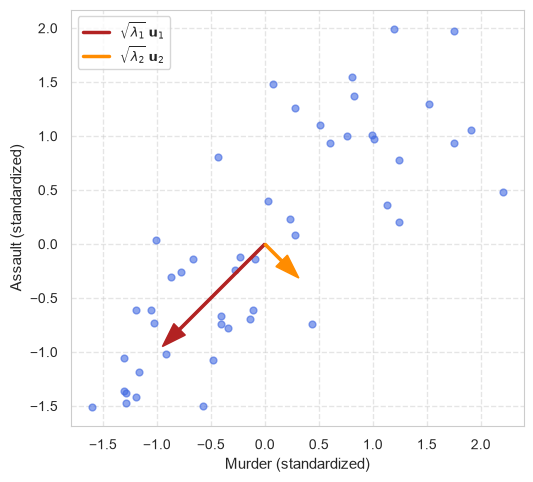

In [12]:
pve_us = lambda_us / lambda_us.sum()
display(Markdown(rf"$\sqrt{{\lambda_1}} = {np.sqrt(lambda_us[0]):.2f}$, $\sqrt{{\lambda_2}} = {np.sqrt(lambda_us[1]):.2f}$; "
                 rf"proportion of variance explained: {pve_us[0]:.2f} and {pve_us[1]:.2f}"))
hp.plot_directions(X_us, {r"$\sqrt{\lambda_1}\,\mathbf{u}_1$": np.sqrt(lambda_us[0]) * U_us[:, 0],
                          r"$\sqrt{\lambda_2}\,\mathbf{u}_2$": np.sqrt(lambda_us[1]) * U_us[:, 1]},
                   xlabel=us.columns[0] + " (standardized)", ylabel=us.columns[1] + " (standardized)")

### Full US Arrests Analysis

- All four components of the data set 

In [13]:
X_full = standardize(us.to_numpy(dtype=float))
Z_f, U_f, lambda_f = pca(X_full)
pd.DataFrame(U_f, index=us.columns, columns=[f"u_{m + 1}" for m in range(U_f.shape[1])]).round(3)    # loading vectors in the columns

,u_1,u_2,u_3,u_4
Murder,-0.536,0.418,-0.341,0.649
Assault,-0.583,0.188,-0.268,-0.743
UrbanPop,-0.278,-0.873,-0.378,0.134
Rape,-0.543,-0.167,0.818,0.089


> 📝 **Note:** A principal direction is unique only **up to its sign**: $-\mathbf{u}_m$ is an equally good direction (with scores $-z_{nm}$). Different software may flip signs; the interpretation stays the same.

### Why Standardize? PCA on the Raw US Arrests

- Without standardization, *Assault* (hundreds of arrests per 100,000) has by far the largest variance, so the first direction simply points at it.

In [14]:
X_centered = us.to_numpy(dtype=float) - us.to_numpy(dtype=float).mean(axis=0)     # centered, not scaled
Z_raw, U_raw, lambda_raw = pca(X_centered)
display(Markdown(rf"Raw data: $\mathbf{{u}}_1 = ({', '.join(f'{v:.3f}' for v in U_raw[:, 0])})^\mathrm{{T}}$ for ({', '.join(us.columns)}); "
                 f"proportion of variance explained by the first component: {lambda_raw[0] / lambda_raw.sum():.3f}"))

Raw data: $\mathbf{u}_1 = (0.042, 0.995, 0.046, 0.075)^\mathrm{T}$ for (Murder, Assault, UrbanPop, Rape); proportion of variance explained by the first component: 0.966

- Visualizing the impact of variables on each component can be done using heat maps

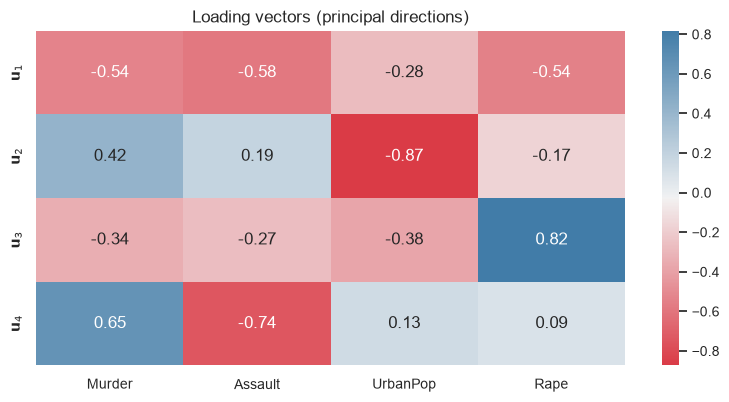

In [15]:
hp.plot_loading_heatmap(
    U_f.T,
    x_labels=list(us.columns),
    y_labels=[rf"$\mathbf{{u}}_{m + 1}$" for m in range(U_f.shape[1])],
    title="Loading vectors (principal directions)",
)

### Proportion of Variance Explained

- Component $m$ explains the share $\lambda_m / \sum_{j=1}^{D} \lambda_j$ of the total variance.
- How many components? Look for an **elbow** in the scree plot; there is no objective rule. When the components feed a supervised model, choose their number by cross-validation (below).

Proportion of variance explained: $z_1$: 0.620, $z_2$: 0.247, $z_3$: 0.089, $z_4$: 0.043; first two together: 0.868

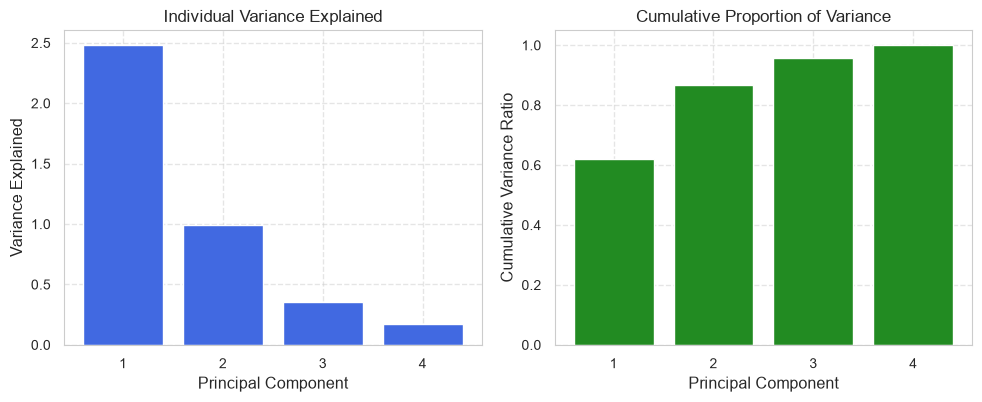

In [16]:
pve_f = lambda_f / lambda_f.sum()
display(Markdown("Proportion of variance explained: " + ", ".join(f"$z_{m + 1}$: {p:.3f}" for m, p in enumerate(pve_f))
                 + f"; first two together: {pve_f[:2].sum():.3f}"))
hp.plot_variance_explained(lambda_f)

### Principal Components as the Best Approximation

- The first $M$ components give the best $M$-dimensional approximation of the data (smallest sum of squared errors):

$$
x_{ni} \approx \sum_{m=1}^{M} z_{nm}\, u_{im}, \qquad \mathbf{X} \approx \mathbf{Z}_M \mathbf{U}_M^\mathrm{T}
$$

- With $\mathrm{RSS}$ the squared error of this approximation and $\mathrm{TSS} = \sum_{n,i} x_{ni}^2$ (centered data), the proportion of variance explained by the first $M$ components is $1 - \mathrm{RSS}/\mathrm{TSS}$, the $R^2$ of Lecture 02.

In [17]:
def reconstruct(Z, U, M):
    """Approximation Z_M U_M^T of the data from its first M principal components."""
    return Z[:, :M] @ U[:, :M].T

tss = np.sum(X_full ** 2)
for M in range(1, X_full.shape[1] + 1):
    rss = np.sum((X_full - reconstruct(Z_f, U_f, M)) ** 2)
    display(Markdown(rf"$M = {M}$: $1 - \mathrm{{RSS}}/\mathrm{{TSS}} = {1 - rss / tss:.3f}$, cumulative proportion of variance explained ${pve_f[:M].sum():.3f}$"))

$M = 1$: $1 - \mathrm{RSS}/\mathrm{TSS} = 0.620$, cumulative proportion of variance explained $0.620$

$M = 2$: $1 - \mathrm{RSS}/\mathrm{TSS} = 0.868$, cumulative proportion of variance explained $0.868$

$M = 3$: $1 - \mathrm{RSS}/\mathrm{TSS} = 0.957$, cumulative proportion of variance explained $0.957$

$M = 4$: $1 - \mathrm{RSS}/\mathrm{TSS} = 1.000$, cumulative proportion of variance explained $1.000$

### PCA Biplot Interpretation

+ Biplot shows both principal component scores and loadings

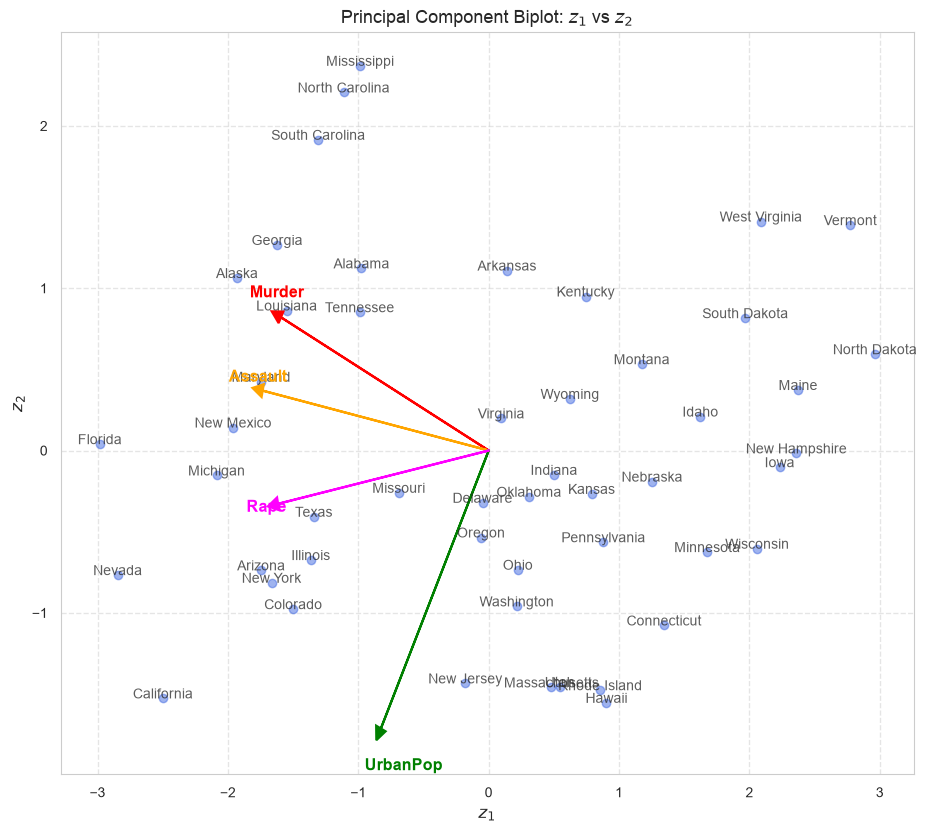

In [18]:
z1, z2 = 0, 1
hp.plot_pca_biplot(z1, z2, Z_f, U_f.T, states, us.columns, colors=['red', 'orange', 'green', 'magenta'])

+ State names - scores for the first two principal components
+ Arrows - the loading vectors of the first two principal components (scaled to the plot)
+ First loading vector places appr. equal weight on *Assault*, *Murder* and *Rape* - roughly - measure of overall rates of serious crimes
    - Three "crime" variables are correlated - states with a high rate in one crime tend to have higher rates in other crimes
+ Second vector places most weight on *UrbanPop* and much less on other features
+ The signs are arbitrary: here high crime rates point to the left; flipping the sign of a component mirrors the plot
+ Score vectors:
    - California high urbanization and crime rate
    - Vermont low urbanization and low crime rate
    - Florida high crime rate and average urbanization

### Multidimensional Exploration: The Iris Benchmark

- Consider a data set containing measurement of 150 iris flowers:
    - 3 types of flowers: setosa, versicolor, and virginica
    - 4 features: width and length of sepal and petal leaves


<center>
    <img src="https://raw.githubusercontent.com/konstantin-schekotihin/dl_course/master/shared/images/slide8.png" width="50%"/>
</center>

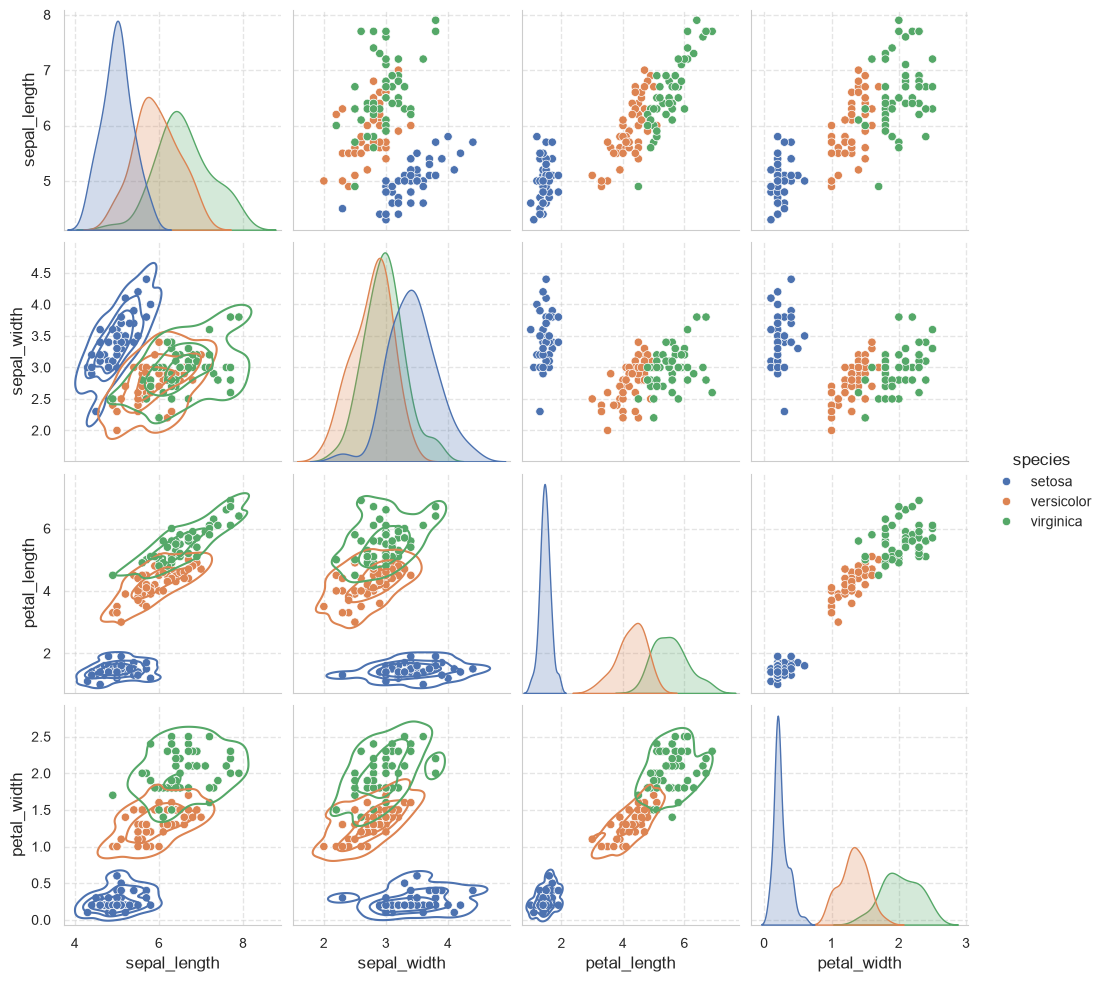

In [19]:
# Load Iris dataset
iris = sns.load_dataset("iris")
fig = sns.pairplot(iris, hue="species")
fig.map_lower(sns.kdeplot, levels=4, color=".2");

In [20]:
X_iris = standardize(iris.iloc[:, 0:4].to_numpy(dtype=float))
Z_i, U_i, lambda_i = pca(X_iris)
pd.DataFrame(U_i, index=iris.columns[0:4], columns=[f"u_{m + 1}" for m in range(4)]).round(3)      # loading vectors in the columns

,u_1,u_2,u_3,u_4
sepal_length,0.521,-0.377,0.720,0.261
sepal_width,-0.269,-0.923,-0.244,-0.124
petal_length,0.580,-0.024,-0.142,-0.801
petal_width,0.565,-0.067,-0.634,0.524


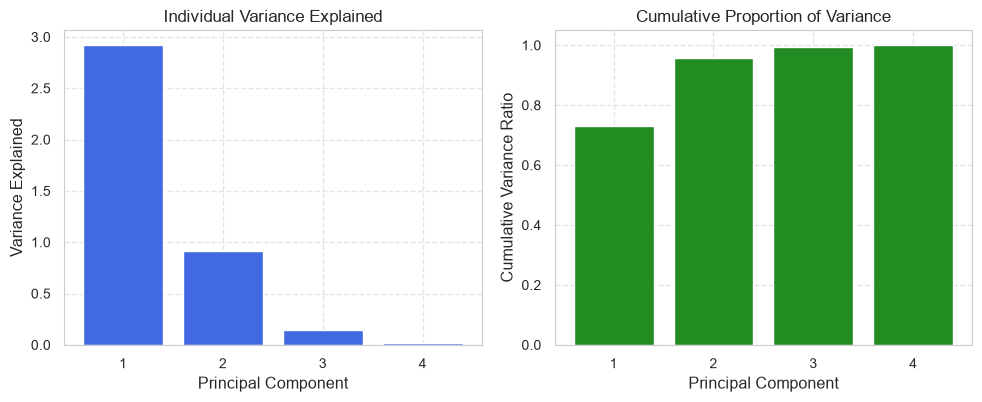

In [21]:
hp.plot_variance_explained(lambda_i)

- Biplot for the two first principal components of iris data set

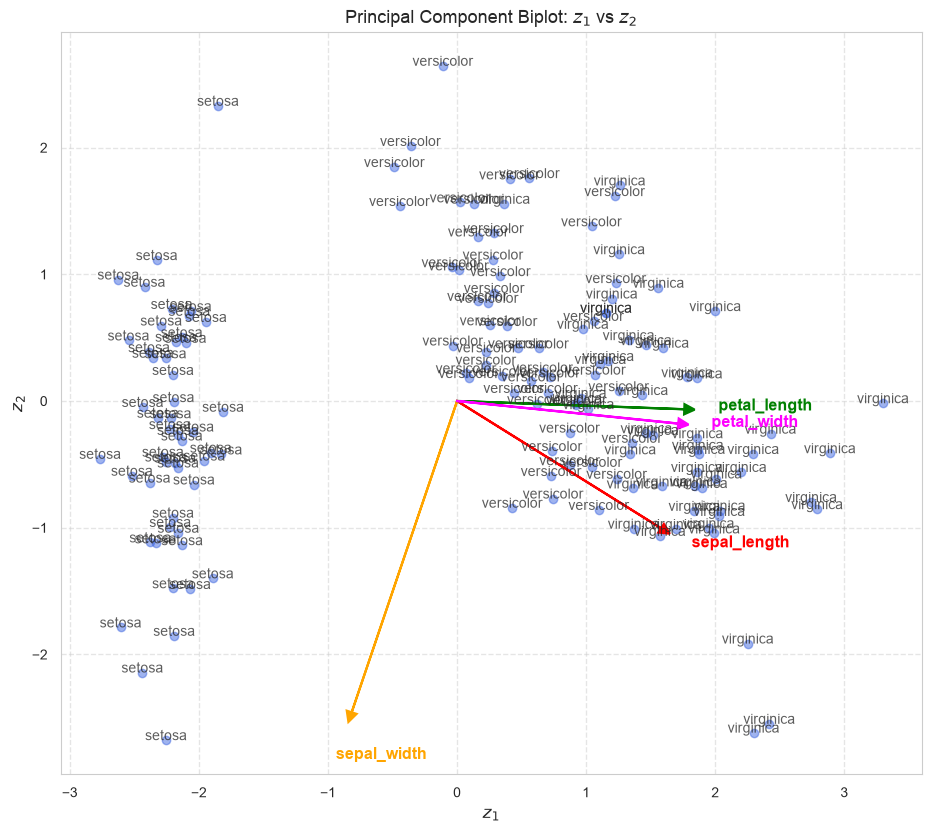

In [22]:
z1, z2 = 0, 1
hp.plot_pca_biplot(z1, z2, Z_i, U_i.T, iris["species"], iris.columns,
                   colors=['red', 'orange', 'green', 'magenta'])

### Other Uses of PCA: Principal Components Regression

- Use the first $M$ principal components $z_1, \dots, z_M$ as features of a linear regression (Lecture 02) instead of the $D$ original features.
- Assumption: the directions in which the features vary most are also the ones associated with the target. This often holds, but nothing guarantees it.
- PCR is not feature selection: every component is a combination of all features. Its effect is close to ridge regression.
- Standardize first, and choose $M$ by cross-validation; $M = D$ components reproduce OLS, so the CV also compares PCR with OLS. Hitters (Lecture 02): same training/test halves as there.

<small>📖 *Source: [James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). An Introduction to Statistical Learning with Applications in Python, Ch. 6: Linear Model Selection and Regularization. Springer](https://doi.org/10.1007/978-3-031-38747-0_6)*</small>

CV chooses $M = 6$ components (CV MSE 134,795; with all $M = 19$ components PCR is OLS: 143,816). Test MSE of the chosen model, evaluated once: 108,196

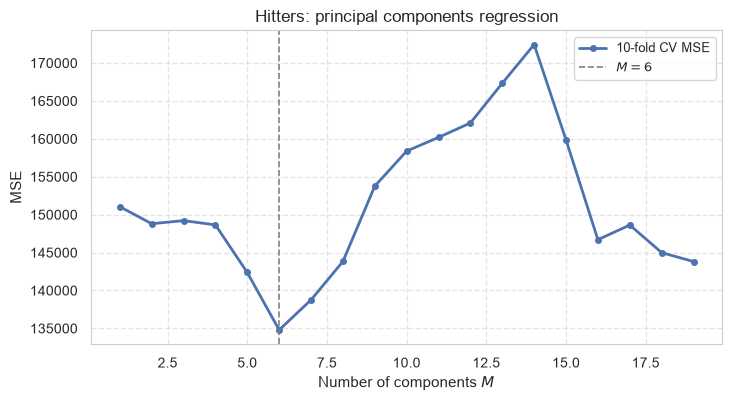

In [23]:
hitters = pd.read_csv(hp.get_file("Hitters.csv")).dropna()
X_hit = pd.get_dummies(hitters.drop(columns="Salary"), drop_first=True, dtype=float)
X_hit_train, X_hit_test, t_hit_train, t_hit_test = train_test_split(X_hit, hitters.Salary, test_size=0.5, random_state=1)

folds = KFold(n_splits=10, shuffle=True, random_state=1)
cv_mse = [-cross_val_score(make_pipeline(StandardScaler(), PCA(n_components=M), LinearRegression()), X_hit_train, t_hit_train,
                           cv=folds, scoring="neg_mean_squared_error").mean() for M in range(1, X_hit.shape[1] + 1)]
M_best = int(np.argmin(cv_mse)) + 1
pcr = make_pipeline(StandardScaler(), PCA(n_components=M_best), LinearRegression()).fit(X_hit_train, t_hit_train)
display(Markdown(f"CV chooses $M = {M_best}$ components (CV MSE {cv_mse[M_best - 1]:,.0f}; with all $M = {X_hit.shape[1]}$ components PCR is OLS: {cv_mse[-1]:,.0f}). "
                 f"Test MSE of the chosen model, evaluated once: {mean_squared_error(t_hit_test, pcr.predict(X_hit_test)):,.0f}"))
hp.plot_curves(np.arange(1, X_hit.shape[1] + 1), {"10-fold CV MSE": cv_mse}, xlabel="Number of components $M$", ylabel="MSE",
               title="Hitters: principal components regression", mark_x=M_best, mark_label=f"$M = {M_best}$")

### Low-Rank Approximation: Image Compression

+ Treat each colour channel of an image as a matrix and keep only its $M$ largest singular values (the SVD behind PCA).
+ The channels are not centered, so this is a low-rank (SVD) approximation rather than PCA in the strict sense.
+ Storage per channel: $M (\text{rows} + \text{columns} + 1)$ numbers instead of $\text{rows} \times \text{columns}$.

Image 320 × 400 pixels; with $M = 15$: 10,815 instead of 128,000 numbers per channel

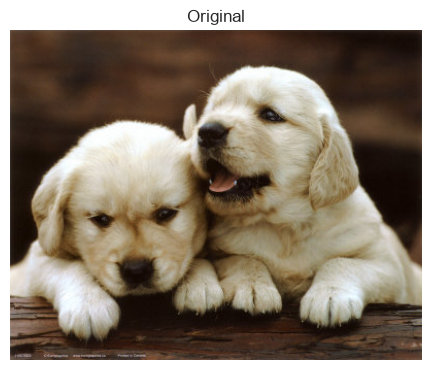

In [24]:
img = mpimg.imread(hp.get_file("puppy.jpeg")) / 255.0                  # pixel values in [0, 1]
channel_svds = [np.linalg.svd(img[:, :, c], full_matrices=False) for c in range(3)]

def low_rank(svd, M):
    """Best rank-M approximation L_M diag(sigma_M) V_M^T of a matrix from its SVD."""
    L, sigma, V_T = svd
    return L[:, :M] @ np.diag(sigma[:M]) @ V_T[:M]

rows, cols, _ = img.shape
display(Markdown(f"Image {rows} × {cols} pixels; with $M = 15$: {15 * (rows + cols + 1):,} instead of {rows * cols:,} numbers per channel"))
hp.plot_image(img, title="Original", figsize=(4.5, 4.5))

In [25]:
def show_compression(M=15):
    """Show the image rebuilt from the first M singular values of each colour channel."""
    approximation = np.stack([low_rank(svd, M) for svd in channel_svds], axis=-1).clip(0, 1)
    hp.plot_image(approximation, title=f"M = {M} of {min(rows, cols)} singular values", figsize=(4.5, 4.5))

In [26]:
interact(show_compression, M=(5, 300, 5));

interactive(children=(IntSlider(value=15, description='M', max=300, min=5, step=5), Output()), _dom_classes=('…

## 3. Clustering Algorithms

### Grouping Observations into Cohesive Subsets
- *Clustering* refers to an unsupervised family of methods for finding subgroups, or *clusters*, in a dataset.
- Every group is distinct and comprises observations that can be considered *similar*.

> ❓ **Core Problem:** What actually does "similar" mean? How can we quantify the similarity or distance between two or more observations?

<small>📖 *Source: [James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). An Introduction to Statistical Learning with Applications in Python, Ch. 12: Unsupervised Learning. Springer](https://doi.org/10.1007/978-3-031-38747-0_12)*</small>

### Distance & Similarity Measures in Clustering

- Clustering groups observations based on pairwise dissimilarity.
- Recall the **Minkowski distance family** *(from Lecture 01)*:
  - In continuous clustering, the most prevalent metric is the **squared Euclidean distance** ($L_2^2$):

$$
d^2(\mathbf{x}_n, \mathbf{x}_{n'}) = \|\mathbf{x}_n - \mathbf{x}_{n'}\|_2^2 = \sum_{i=1}^{D} (x_{ni} - x_{n'i})^2
$$

- **Correlation-based distance** $1 - r(\mathbf{x}_n, \mathbf{x}_{n'})$, with $r$ the correlation of the two observation *profiles*: two observations are close if their features go up and down together, even if their levels differ (e.g. shoppers who buy the same kinds of items, in different amounts).

> ⚠️ **Important:** Euclidean distances grow with the feature variances: standardize features measured in different units before clustering. With features in the same units (Iris: all in cm) standardizing is a modelling choice.

In [27]:
# Euclidean vs. correlation-based distance between three states (standardized US Arrests)
three = ["Alabama", "Alaska", "Vermont"]
X_three = X_full[[list(states).index(s) for s in three]]
print(pd.DataFrame(squareform(pdist(X_three, "euclidean")), index=three, columns=three).round(2), "\n")
print(pd.DataFrame(squareform(pdist(X_three, "correlation")), index=three, columns=three).round(2))

         Alabama  Alaska  Vermont
Alabama     0.00    2.70     3.98
Alaska      2.70    0.00     4.87
Vermont     3.98    4.87     0.00 

         Alabama  Alaska  Vermont
Alabama     0.00    0.71     0.40
Alaska      0.71    0.00     0.08
Vermont     0.40    0.08     0.00


### Within-Cluster Variation Measure

- Partition the indices of $N$ observations into $K$ disjoint clusters $\mathcal{S}_1, \dots, \mathcal{S}_K$ such that $\bigcup_{k=1}^K \mathcal{S}_k = \{1, \dots, N\}$ and $\mathcal{S}_k \cap \mathcal{S}_l = \emptyset$ for $k \neq l$.
- The total **within-cluster variation** objective measures aggregate cluster dispersion:

$$
J = \sum_{k=1}^{K} \frac{1}{2|\mathcal{S}_k|} \sum_{n \in \mathcal{S}_k} \sum_{n' \in \mathcal{S}_k} \|\mathbf{x}_n - \mathbf{x}_{n'}\|^2 = \sum_{k=1}^{K} \sum_{n \in \mathcal{S}_k} \|\mathbf{x}_n - \boldsymbol{\mu}_k\|^2
$$

- Here $\boldsymbol{\mu}_k = \frac{1}{|\mathcal{S}_k|} \sum_{n \in \mathcal{S}_k} \mathbf{x}_n$ is the **mean centroid** of cluster $\mathcal{S}_k$.
- Minimizing pairwise squared distances within each cluster is mathematically identical to minimizing squared deviations from cluster centroids!


### Overview of Clustering Approaches

- *$K$-means*: partition the observations into a predefined number $K$ of clusters
- *Hierarchical clustering*: create a dendrogram -- a tree-like visual representation of the observations -- representing all possible clusters, from 1 (root) to $N$ (leaves)
- *DBSCAN*: Density-Based Spatial Clustering of Applications with Noise, where the notion of density is defined as the number of points within a specified radius $\epsilon$

### The $K$-Means Objective Function

- $K$-Means optimizes the distortion measure $J$ over cluster assignments and centroids:

$$
\min_{\mathcal{S}_1, \dots, \mathcal{S}_K} J = \min_{\mathcal{S}_1, \dots, \mathcal{S}_K} \sum_{k=1}^{K} \sum_{n \in \mathcal{S}_k} \|\mathbf{x}_n - \boldsymbol{\mu}_k\|^2
$$

- There are almost $K^N$ ways to partition $N$ observations into $K$ clusters, far too many to try; $K$-Means uses a fast iterative two-step coordinate descent (Lloyd's algorithm).

### Lloyd's Algorithm for $K$-Means

1. **Initialize**: randomly assign each observation to one of the $K$ clusters (alternatively: choose $K$ random observations as initial centroids).
2. **Update Step**: compute each centroid $\boldsymbol{\mu}_k$ as the mean of its members (formula below).
3. **Assignment Step**: assign each observation $\mathbf{x}_n$ to its nearest centroid:

$$
c_n = \arg\min_{k \in \{1, \dots, K\}} \|\mathbf{x}_n - \boldsymbol{\mu}_k\|^2
$$

   with the centroids

$$
\boldsymbol{\mu}_k = \frac{1}{|\mathcal{S}_k|} \sum_{n \in \mathcal{S}_k} \mathbf{x}_n
$$

4. **Iterate**: repeat steps 2 and 3 until the cluster assignments no longer change.

### Properties and Convergence of $K$-Means

+ Neither step can increase the objective $J$: the update step finds the best centroids for the current clusters, the assignment step the best clusters for the current centroids
+ Hence the algorithm stops after finitely many steps, but at a **local** optimum, which depends on the random start
+ Run the algorithm several times with different random starts and keep the solution with the smallest $J$
+ Better initializations, such as $K$-means++, reduce the risk of a poor start

In [28]:
X_iris_cm = iris.iloc[:, 0:4].to_numpy()          # Iris in cm: all features in the same units

def lloyd(X, K, rng, max_iter=100):
    """K-means by Lloyd's algorithm from a random initial assignment; returns labels, centroids and J after each iteration."""
    labels = rng.integers(K, size=len(X))
    history = []
    for _ in range(max_iter):
        centroids = np.array([X[labels == k].mean(axis=0) if np.any(labels == k) else X[rng.integers(len(X))]
                              for k in range(K)])                            # update step (re-seed an empty cluster)
        sq_dist = ((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)
        new_labels = sq_dist.argmin(axis=1)                                   # assignment step
        history.append(sq_dist[np.arange(len(X)), new_labels].sum())          # objective J
        if np.array_equal(new_labels, labels):
            break
        labels = new_labels
    return labels, centroids, history

rng = np.random.default_rng(1)
for start in range(6):
    labels, centroids, history = lloyd(X_iris_cm, K=3, rng=rng)
    display(Markdown(f"start {start + 1}: {len(history)} iterations, $J$ = " + " → ".join(f"{j:.1f}" for j in history[:3]) + f" … → **{history[-1]:.2f}**"))

start 1: 12 iterations, $J$ = 543.9 → 94.6 → 86.4 … → **78.86**

start 2: 13 iterations, $J$ = 567.7 → 155.0 → 145.7 … → **142.75**

start 3: 12 iterations, $J$ = 566.1 → 100.3 → 87.3 … → **78.86**

start 4: 10 iterations, $J$ = 654.3 → 120.3 → 83.9 … → **78.86**

start 5: 4 iterations, $J$ = 602.9 → 149.6 → 145.5 … → **145.45**

start 6: 5 iterations, $J$ = 671.1 → 122.9 → 81.5 … → **78.85**

### Improved Centroid Initialization: $K$-Means++

- Standard random initialization often converges to poor local minima.
- **$K$-Means++ Algorithm**:
  1. Select the first centroid $\boldsymbol{\mu}_1$ uniformly at random from observations $\{\mathbf{x}_n\}$.
  2. For each sample $\mathbf{x}_n$, compute shortest distance $d(\mathbf{x}_n)$ to existing centroids.
  3. Choose the next centroid with probability proportional to squared distance:

$$
p(\mathbf{x}_n) = \frac{d(\mathbf{x}_n)^2}{\sum_{m=1}^{N} d(\mathbf{x}_m)^2}
$$

  4. Repeat until all $K$ centroids are initialized.

- **Theoretical Guarantee**: Achieves $\mathcal{O}(\log K)$ competitive ratio to optimal clustering.


$J$ = 78.85. Cluster numbers are arbitrary: compare them with the species in a table, never rename them

species  setosa  versicolor  virginica
cluster                               
0             0          48         14
1            50           0          0
2             0           2         36


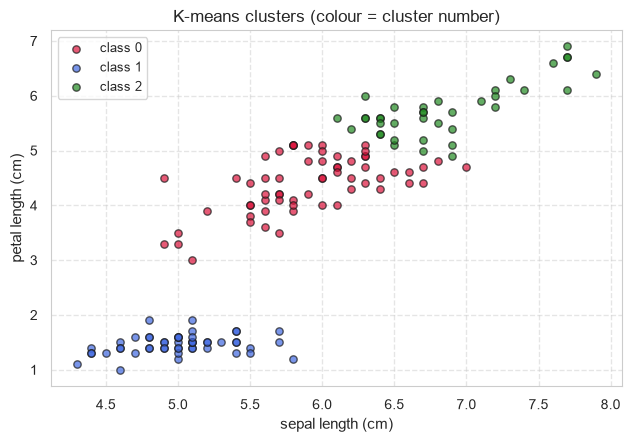

In [29]:
km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X_iris_cm)       # 10 starts (k-means++), keep the best
display(Markdown(f"$J$ = {km.inertia_:.2f}. Cluster numbers are arbitrary: compare them with the species in a table, never rename them"))
print(pd.crosstab(pd.Series(km.labels_, name="cluster"), iris["species"]))
hp.plot_classes_2d(X_iris_cm[:, [0, 2]], km.labels_, xlabel="sepal length (cm)", ylabel="petal length (cm)",
                   title="K-means clusters (colour = cluster number)")

### Hard vs. Soft Clustering

- *Hard clustering*: each observation is assigned to exactly one cluster
- *Soft (fuzzy) clustering*: might assign an observation to multiple clusters


- *Fuzzy $c$-means* replaces the assignments by probabilities for each observation to belong to each cluster
    - For instance, the fact that an observation $\mathbf{x}_1$ is associated more with the second cluster than with the first can be expressed by the memberships $u_{11} = 0.2$ and $u_{12} = 0.8$

### Fuzzy $c$-Means Clustering

- Relaxes hard cluster assignments by computing continuous **fuzzy membership weights** $u_{nk} \in [0, 1]$ (with $\sum_{k=1}^K u_{nk} = 1$):

$$
u_{nk} = \left[ \sum_{j=1}^{K} \left( \frac{\|\mathbf{x}_n - \boldsymbol{\mu}_k\|}{\|\mathbf{x}_n - \boldsymbol{\mu}_j\|} \right)^{\frac{2}{m-1}} \right]^{-1}
$$

  where $m > 1$ is the **fuzziness exponent** controlling cluster overlap.
- Iterative coordinate descent updates centroids $\boldsymbol{\mu}_k = \frac{\sum_n u_{nk}^m \mathbf{x}_n}{\sum_n u_{nk}^m}$ until membership weights stabilize.


### Determining the Optimal Number of Clusters

+ Finding the right $K$ is hard because there are no labels to test against; it is a judgment call
+ Elbow plot:
    - Compute $K$-means for different $K$, say $K = 1, \dots, 8$
    - Get the within-cluster variation $J$ for each $K$
    - $J$ always decreases as $K$ grows: look for the $K$ after which it decreases only slowly (the "elbow")
+ Hierarchical clustering shows the solutions for all $K$ at once

$J$ for $K = 1, \dots, 8$: 681.4, 152.3, 78.9, 57.2, 46.4, 39.0, 34.4, 30.1

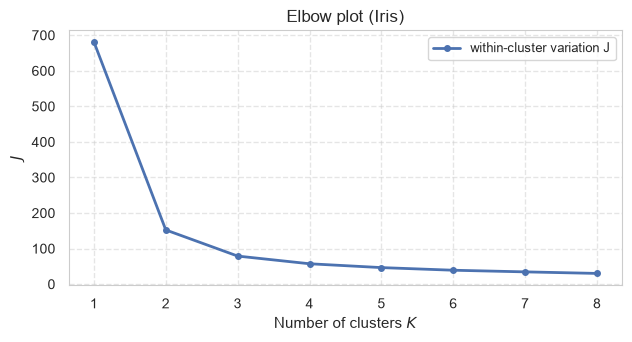

In [30]:
K_values = np.arange(1, 9)
J_values = [KMeans(n_clusters=K, n_init=10, random_state=0).fit(X_iris_cm).inertia_ for K in K_values]
display(Markdown("$J$ for $K = 1, \\dots, 8$: " + ", ".join(f"{j:.1f}" for j in J_values)))
hp.plot_curves(K_values, {"within-cluster variation J": J_values}, xlabel="Number of clusters $K$", ylabel="$J$",
               title="Elbow plot (Iris)", figsize=(6.5, 3.6))

### Density-Based Clustering: DBSCAN
+ Classify observations based on their density in the feature space
+ Makes no assumption on a shape of clusters
+ DBSCAN assigns a label to each observation as follows:
    - **Core point**: at least a specified number of points *MinPts* are within the specified radius $\epsilon$
    - **Border point**: an observation that has fewer observations in the radius $\epsilon$ than *MinPts*, but is in the radius of a core point
    - **Noise point**: all other points

### The DBSCAN Algorithm & Core Points

1. Create a separate cluster for every set of core points such that every point of this set is in the $\epsilon$ radius of other core points of the same set
2. Assign each border element to a cluster, where its core point is

- Possible disadvantages:
    + High number of features wrt. the number of observations might result in reduction of performance
    + Selection of hyperparameters *MinPts* and $\epsilon$ can be problematic
- Spectral clustering methods: use PCA-like approach and focus on spectrum (eigenvalues) of the similarity matrix, to perform dimensionality reduction prior to clustering

DBSCAN finds 2 clusters and 11 noise points (label -1)

species  setosa  versicolor  virginica
cluster                               
-1            1           5          5
 0           49           0          0
 1            0          45         45


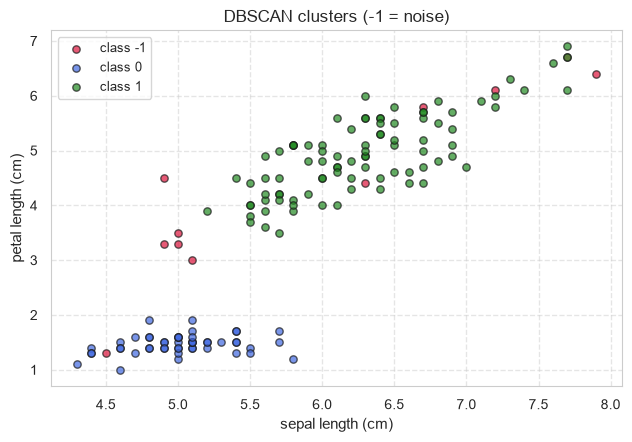

In [31]:
db = DBSCAN(eps=0.55, min_samples=5).fit(X_iris_cm)
display(Markdown(f"DBSCAN finds {len(set(db.labels_) - {-1})} clusters and {np.sum(db.labels_ == -1)} noise points (label -1)"))
print(pd.crosstab(pd.Series(db.labels_, name="cluster"), iris["species"]))
hp.plot_classes_2d(X_iris_cm[:, [0, 2]], db.labels_, xlabel="sepal length (cm)", ylabel="petal length (cm)",
                   title="DBSCAN clusters (-1 = noise)")

### Hierarchical Clustering & Dendrograms

+ Hierarchical clustering does not require choosing the number of clusters $K$ in advance
+ But it requires choosing a dissimilarity measure, a linkage, and where to cut the tree
+ Can be of two types: bottom-up or agglomerative as well as top-down or divisive
+ Here we consider the agglomerative variant, which is the most common type of hierarchical clustering
+ Dendrogram is built starting from the leaves and combining clusters up to the trunk

### Agglomerative Clustering & Linkage Criteria

**Algorithm**:

1. Start with each observation in its own cluster; compute all $\binom{N}{2}$ pairwise dissimilarities.
2. Merge the two clusters that are **least dissimilar**; the dissimilarity at which they merge is the **fusion height** in the dendrogram.
3. Update the dissimilarities between the new cluster and the others with a **linkage**, and repeat until one cluster is left.

| Linkage | Dissimilarity between clusters $A$ and $B$ |
| :--- | :--- |
| Complete | largest dissimilarity between a point of $A$ and a point of $B$ |
| Single | smallest dissimilarity between a point of $A$ and a point of $B$ |
| Average | average of all dissimilarities between points of $A$ and points of $B$ |
| Centroid | dissimilarity between the centroids of $A$ and $B$ |

- Complete and average linkage give balanced trees; single linkage tends to chain observations one at a time.

### Hierarchical Clustering: Case Study

- The standardized US Arrests (§2), clustered with Euclidean distance and three linkages.
- **Reading a dendrogram**: two states are similar if they fuse **low** in the tree. Their horizontal closeness means nothing; branches can be rotated freely.
- Cutting the tree at a height gives clusters; here the complete-linkage tree is cut into $3$ clusters.

complete linkage, cut into 3 clusters: sizes [31, 11, 8]

average linkage, cut into 3 clusters: sizes [30, 19, 1]

single linkage, cut into 3 clusters: sizes [48, 1, 1]

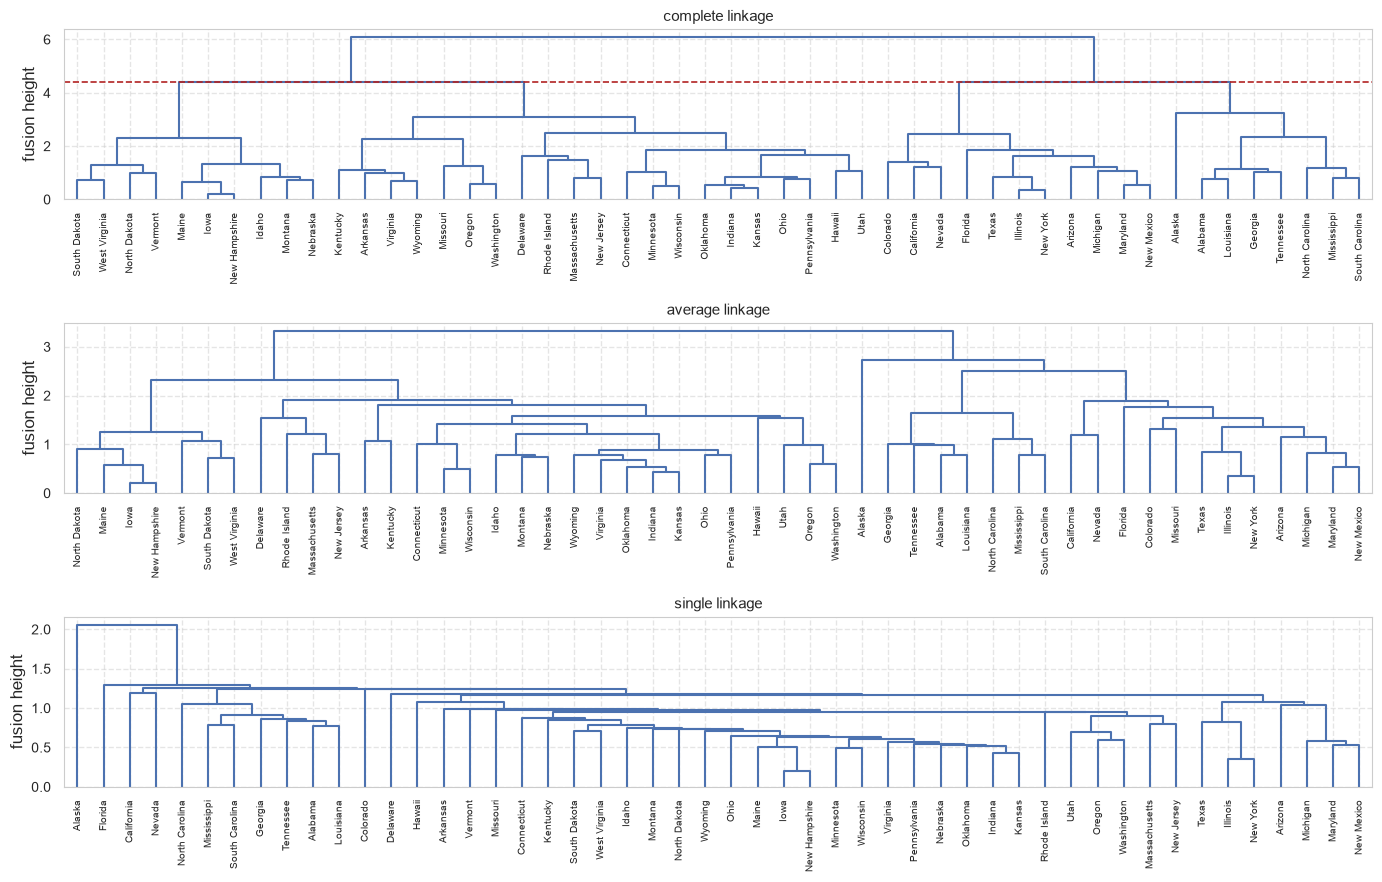

In [32]:
linkages = {f"{method} linkage": linkage(X_full, method=method, metric="euclidean") for method in ("complete", "average", "single")}
for name, Z in linkages.items():
    sizes = np.bincount(fcluster(Z, t=3, criterion="maxclust"))[1:]
    display(Markdown(f"{name}, cut into 3 clusters: sizes {sorted(sizes.tolist(), reverse=True)}"))
cut_height = linkages["complete linkage"][-3:-1, 2].mean()        # halfway between the fusions that leave 3 and 2 clusters
hp.plot_dendrograms(linkages, labels=list(states), cut_heights={"complete linkage": cut_height}, figsize=(14, 9))

In [33]:
# Fusion height vs. distance: complete linkage on the standardized US Arrests
fusion_height = squareform(cophenet(linkages["complete linkage"]))
distance = squareform(pdist(X_full))
for a, b in [("Iowa", "New Hampshire"), ("California", "Nevada"), ("Florida", "North Carolina")]:
    i, j = list(states).index(a), list(states).index(b)
    display(Markdown(f"{a} – {b}: distance {distance[i, j]:.2f}, fusion height {fusion_height[i, j]:.2f}"))

Iowa – New Hampshire: distance 0.21, fusion height 0.21

California – Nevada: distance 1.20, fusion height 1.20

Florida – North Carolina: distance 3.00, fusion height 4.42

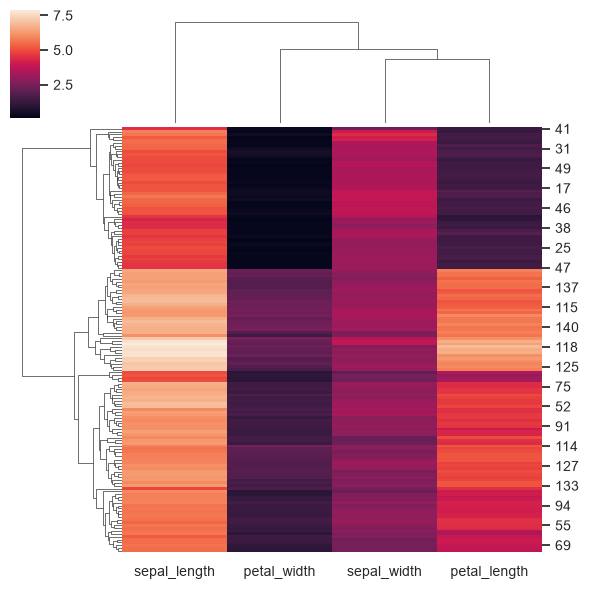

In [34]:
# Heat map of the Iris measurements with dendrograms for rows and columns (average linkage, Euclidean distance)
sns.clustermap(iris.drop(columns="species"), method="average", metric="euclidean", figsize=(6, 6));

### Practical Issues in Clustering

- Small decisions with big consequences: standardize or not, which dissimilarity, which linkage, which $K$ or cut height. Try several and look for patterns that persist.
- Validation is hard: there is no response to check against; any method will find clusters, even in pure noise.
- Outliers that belong to no group can distort the clusters ($K$-means forces every point into a cluster; DBSCAN can label them noise).
- Clusters are not robust: removing a few observations can change them considerably.
- Report clusters as hypotheses for further study, not as established facts.

<small>📖 *Source: [James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). An Introduction to Statistical Learning with Applications in Python, Ch. 12: Unsupervised Learning. Springer](https://doi.org/10.1007/978-3-031-38747-0_12)*</small>

## 4. Algorithm Selection Card: Unsupervised Learning (PCA & Clustering)

| Dimension | Assessment & Practical Guidance |
| :--- | :--- |
| **Best Suited For** | Exploratory data analysis, dimensionality reduction ($D \to 2$ or $3$ for visualization), latent feature extraction, and discovering natural groupings without ground-truth labels. |
| **Key Hyperparameters** | • **PCA**: Number of components $M$ or explained variance ratio threshold (e.g. $95\%$).<br>• **$K$-Means**: Number of clusters $K$ (tune via Elbow curve / Silhouette score); initialization (`k-means++`).<br>• **DBSCAN**: Neighborhood radius $\epsilon$ and minimum density samples `min_samples`.<br>• **Hierarchical**: Linkage criterion (`ward`, `complete`, `average`) and distance metric. |
| **Interpretability vs. Capacity** | **High Interpretability (Linear PCA / Centroids)**: Principal directions show exact feature loadings; cluster centroids summarize average cluster profiles. |
| **Critical Pitfalls** | • **Feature Scaling**: standardize features measured in different units before PCA and distance-based clustering ($K$-Means, DBSCAN, hierarchical).<br>• **Local optima**: run $K$-means with several starts (`n_init`) and keep the smallest $J$.<br>• **Cluster Assumptions**: $K$-Means assumes spherical, equally-sized clusters; use DBSCAN for arbitrary non-convex geometries or density variations.<br>• **Curse of Dimensionality**: Distance metrics lose contrast in high dimensions; run PCA before clustering when $D$ is large. |

> 💡 **Key Takeaway:** Unsupervised learning uncovers latent geometry and groupings without supervisor feedback. Standardize features measured in different units, check clusters across several methods and settings, and assess PCA explained variance before downstream modeling.